In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal, Annotated
from dotenv import load_dotenv
import os
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage, SystemMessage
from pydantic import BaseModel, Field

In [2]:
load_dotenv()

True

In [3]:
class EvaluationSchema(BaseModel):
    feedback:str = Field(description="feedback for the user")
    eval: Literal["approved", "need_improvment"]= Field(description="final evaluation on the tweet")

In [4]:
llm=ChatGroq(model="openai/gpt-oss-120b", temperature=0.2, api_key=os.getenv("GROQ_API_KEY"))
eval_llm=llm.with_structured_output(EvaluationSchema)

In [13]:
class TweetState(TypedDict):
    topic: str
    tweet: str
    eval: Literal["approve", "need_improvement"]
    feedback: str
    iteration: int
    max_iteration: int

In [14]:
def generate_tweet(state:TweetState)->TweetState:
    
    messages =[
        SystemMessage(content="You are a funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
    Write a short, original, and hilarious tweet on the topic: "{state['topic']}".
        Rules:
        - Do NOT use question-answer format.
        - Max 280 characters.
        - Use observational humor, irony, sarcasm, or cultural references.
        - Think in meme logic, punchlines, or relatable takes.
        - Use simple, day to day english
        - This is version {state['iteration'] + 1}
        """)
        ]
    
    tweet= llm.invoke(messages)
    return{"tweet": tweet}
    
        
    

In [15]:
def Evaluate_tweet(state:TweetState):
    messages = [
    SystemMessage(content="You are a ruthless, no-laugh-given Twitter critic. You evaluate tweets based on humor, originality, virality, and tweet format."),
    HumanMessage(content=f"""
Evaluate the following tweet:

Tweet: "{state['tweet']}"

Use the criteria below to evaluate the tweet:

1. Originality - Is this fresh, or have you seen it a hundred times before?
2. Humor - Did it genuinely make you smile, laugh, or chuckle?
3. Punchiness - Is it short, sharp, and scroll-stopping?
4. Virality Potential - Would people retweet or share it?
5. Format - Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?

Auto-reject if:
- It's written in question-answer format (e.g., "Why did..." or "What happens when...")
- It exceeds 280 characters
- It reads like a traditional setup-punchline joke
- Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., "Masterpieces of the auntie-uncle universe" or vague summaries)

### Respond ONLY in structured format:
- evaluation: "approved" or "needs_improvement"
- feedback: One paragraph explaining the strengths and weaknesses
""")
]
    response= eval_llm.invoke(messages)
    return {"eval":response.eval, "feedback":response.feedback}


In [16]:
def optimizer(state:TweetState):
    messages = [
        SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
        HumanMessage(content=f"""
    Improve the tweet based on this feedback:
    "{state['feedback']}"

    Topic: "{state['topic']}"
    Original Tweet:
    {state['tweet']}

    Re-write it as a short, viral-worthy tweet. Avoid Q&A style and stay under 280 characters.
    """)
    ]
    response=llm.invoke(messages).content
    iteration =state["iteration"]+1
    return{"tweet":response, "iteration":iteration}


In [17]:
def route_evaluation(state:TweetState):
    if state['eval']=='approved' or state['iteration']>=state["max_iteration"]:
        return "approved"
    else:
        return "need_improvement"

In [18]:
graph= StateGraph(TweetState)
graph.add_node("generate",generate_tweet)
graph.add_node("Evaluate",Evaluate_tweet)
graph.add_node("optimizer",optimizer)

graph.add_edge(START,"generate")
graph.add_edge("generate","Evaluate")
graph.add_conditional_edges("Evaluate",route_evaluation,{"approved":END,"need_improvement":"optimizer"})
graph.add_edge("optimizer","Evaluate")

workflow= graph.compile()
    

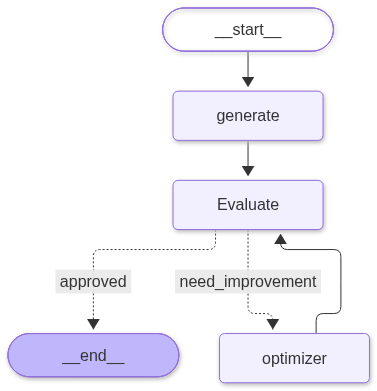

In [19]:
workflow

In [20]:
initial_state={
    'topic':"indian railway",
    'iteration':1,
    "max_iteration":5
    
}
final_state=workflow.invoke(initial_state)
print(final_state)

{'topic': 'indian railway', 'tweet': AIMessage(content='Indian Railways: where the train “arrives on time” if you count a 3‑hour delay as punctual and a 2‑hour ride as a scenic tour of every state’s snack stall. #DesiTravel 🚂🍿', additional_kwargs={'reasoning_content': 'We need to produce a short original hilarious tweet about Indian railway. No Q&A format. Max 280 chars. Use observational humor, irony, sarcasm, cultural references. Simple day to day English. Version 2 maybe just a note. Provide tweet. Ensure no question marks? Not necessarily, but avoid Q&A format. Could include a question but not Q&A. Safer to avoid question marks. Let\'s craft ~200 chars.\n\nTweet: "Indian Railways: where the train arrives on time… if you count the 3‑hour delay as ‘on time’ and the 2‑hour journey as a scenic tour of every state’s snack stall." Count characters. Let\'s count: "Indian Railways: where the train arrives on time… if you count the 3‑hour delay as ‘on time’ and the 2‑hour journey as a sceni